# 04 — Financial Inclusion EDA & Demographic Gap (Orang 1)

**Owner:** rrrafaa | **Data:** Global Findex Indonesia 2024

**Research questions:** How prevalent is account ownership? How does it differ by income, gender, education, age, and rural/urban category? How large are the weighted group gaps?

**Approach:** survey-weighted descriptive EDA, no causal inference. 2024 is a cross-section, not a time series. *Do not publish respondent-level data.*


## 1. Environment and private input

This notebook independently loads original ZIP; it does not depend on runtime state in notebook 01. On Colab, upload the ZIP. Locally, use data/raw/.


In [1]:
from pathlib import Path
import hashlib,io,zipfile,sys,subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
REPO="Indonesia-Financial-Inclusion-Digital-Finance-Analytics"
ZIP="IDN_2024_FINDEX_v02_M_CSV.zip"
CSV="Findex_Microdata_2025_updateIndonesia.csv"
SHA="fc50f0a843e289a3b9784ac81dce1018a8195388608575e6c8315c195073a64c"
root=next((p for p in [Path.cwd(),*Path.cwd().parents,Path("/content")/REPO] if (p/"data/raw/README.md").exists()),None)
if root is None and "google.colab" in sys.modules:
    root=Path("/content")/REPO
    subprocess.run(["git","clone","--depth","1","https://github.com/rrrafaa/"+REPO+".git",str(root)],check=True)
if root is None: raise FileNotFoundError("Run Jupyter from the cloned repo")
raw=root/"data/raw";out=root/"data/processed"
raw.mkdir(parents=True,exist_ok=True);out.mkdir(parents=True,exist_ok=True)
p=next((p for p in [raw/ZIP,Path("/content")/ZIP,Path.cwd()/ZIP] if p.exists()),None)
if p is None and "google.colab" in sys.modules:
    from google.colab import files
    uploaded=files.upload()
    if ZIP not in uploaded: raise FileNotFoundError("Expected original ZIP "+ZIP)
    p=raw/ZIP;p.write_bytes(uploaded[ZIP])
if p is None: raise FileNotFoundError("Place original ZIP in data/raw/"+ZIP)
assert hashlib.sha256(p.read_bytes()).hexdigest()==SHA,"Wrong source ZIP checksum"
with zipfile.ZipFile(p) as z: df=pd.read_csv(io.BytesIO(z.read(CSV)),low_memory=False)
assert df.shape==(1068,199)
assert df.wgt.notna().all() and df.wgt.gt(0).all()
print("Ready:",df.shape)



Saving IDN_2024_FINDEX_v02_M_CSV.zip to IDN_2024_FINDEX_v02_M_CSV.zip
Ready: (1068, 199)


## 2. Derived categories and validity rules

The original dataset already contains core 0/1 financial indicators. Keep unknown answers as missing; preserve the original data unchanged.


In [2]:
d=df.copy()
d["gender"]=d.female.map({1:"Female",2:"Male"})
d["income_quintile"]=d.inc_q.map({1:"Q1 - lowest",2:"Q2",3:"Q3",4:"Q4",5:"Q5 - highest"})
d["education"]=d.educ.map({1:"Primary or less",2:"Secondary",3:"Tertiary or more"})
d["residence"]=d.urbanicity.map({1:"Rural",2:"Urban"})
d["age_group"]=pd.cut(d.age,bins=[14,24,34,44,54,np.inf],labels=["15-24","25-34","35-44","45-54","55+"])
INDICATORS={"account":"Owns any account","account_fin":"Financial institution account","account_mob":"Mobile money account","anydigpayment":"Used digital payment","saved":"Saved money","borrowed":"Borrowed money"}
for key in INDICATORS:
    assert d[key].dropna().isin([0,1]).all(),f"Unexpected code in {key}"
print("Demographic segment labels prepared; respondent-level previews intentionally omitted.")


## 3. Weighted metrics helper

Use **sum(w × indicator) / sum(w)** for valid respondents only. Record unweighted n to flag unstable groups. Compare descriptive gaps in *percentage points*.


In [3]:
def weighted_share(frame,indicator):
    sample=frame.loc[frame[indicator].isin([0,1]) & frame.wgt.gt(0),[indicator,"wgt"]]
    if sample.empty: return (np.nan,0,0.0)
    numerator=(sample[indicator]*sample.wgt).sum()
    denominator=sample.wgt.sum()
    return (100*numerator/denominator,len(sample),float(denominator))

def by_group(group_col,indicator="account"):
    rows=[]
    for key,part in d.groupby(group_col,observed=True,dropna=True):
        rate,n,weight_total=weighted_share(part,indicator)
        rows.append({"dimension":group_col,"group":str(key),"metric":indicator,"rate_pct":round(rate,3),"n_valid":n,"weight_total":weight_total,"small_n_warning":n<30})
    return pd.DataFrame(rows)

overview=pd.DataFrame([{"metric":key,"label":label,"rate_pct":weighted_share(d,key)[0],"n_valid":weighted_share(d,key)[1]} for key,label in INDICATORS.items()])
display(overview.round(2))
assert 50 < overview.loc[overview.metric.eq("account"),"rate_pct"].iloc[0] < 65,"Investigate unexpected national account rate"


## 4. National headline KPIs


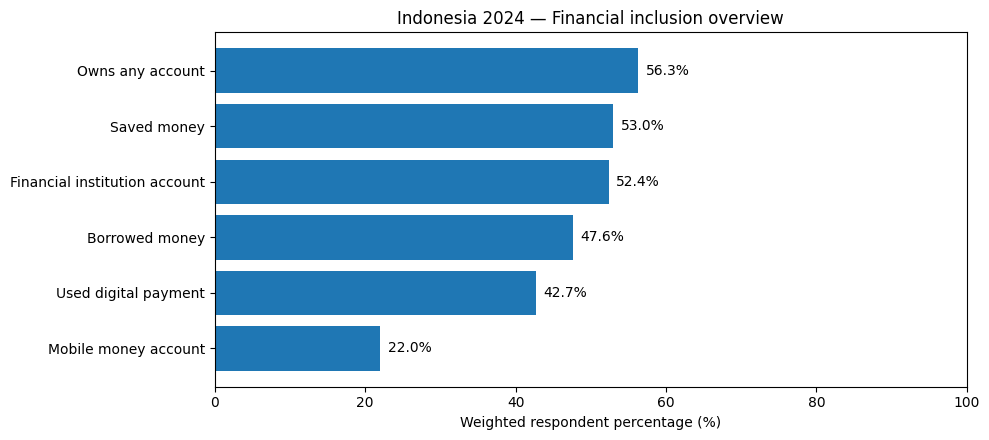

In [4]:
fig,ax=plt.subplots(figsize=(10,4.5))
tmp=overview.sort_values("rate_pct")
ax.barh(tmp.label,tmp.rate_pct)
ax.set_xlim(0,100);ax.set_xlabel("Weighted respondent percentage (%)")
ax.set_title("Indonesia 2024 — Financial inclusion overview")
for i,v in enumerate(tmp.rate_pct): ax.text(v+1,i,f"{v:.1f}%",va="center")
plt.tight_layout();plt.show()


## 5. Account ownership by income quintile

Check the difference Q5 − Q1. Keep income-quintile ordering.


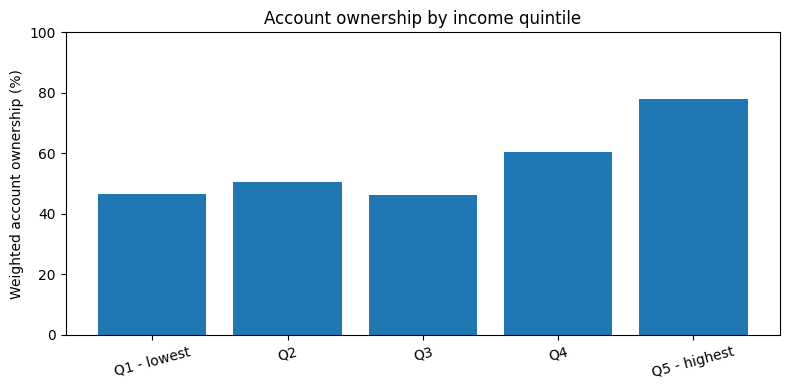

Q5 minus Q1 account ownership gap: 31.6 percentage points


In [5]:
income=by_group("income_quintile")
display(income)
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(income.group,income.rate_pct)
ax.set(ylim=(0,100),ylabel="Weighted account ownership (%)",title="Account ownership by income quintile")
plt.xticks(rotation=15);plt.tight_layout();plt.show()
q1=income.loc[income.group.eq("Q1 - lowest"),"rate_pct"].iloc[0]
q5=income.loc[income.group.eq("Q5 - highest"),"rate_pct"].iloc[0]
print(f"Q5 minus Q1 account ownership gap: {q5-q1:.1f} percentage points")


## 6. Account ownership by gender, education, age group and residence


In [6]:
dimensions=["gender","education","age_group","residence"]
tables=[]
fig,axes=plt.subplots(2,2,figsize=(13,9))
for ax,dim in zip(axes.flat,dimensions):
    t=by_group(dim);tables.append(t)
    ax.barh(t.group,t.rate_pct)
    ax.set_xlim(0,100);ax.set_title("Account ownership — "+dim.replace("_"," ").title())
    ax.set_xlabel("Weighted percentage (%)")
    for i,v in enumerate(t.rate_pct):ax.text(min(v+1,97),i,f"{v:.1f}%",va="center",fontsize=9)
plt.tight_layout();plt.show()
segments=pd.concat([income,*tables],ignore_index=True)
display(segments)
print("Segments with unweighted n < 30:")
display(segments.loc[segments.small_n_warning])


## 7. Multiple indicators by gender and income

`account_fin`, `account_mob`, and `anydigpayment` may overlap. Do not stack them to 100%.


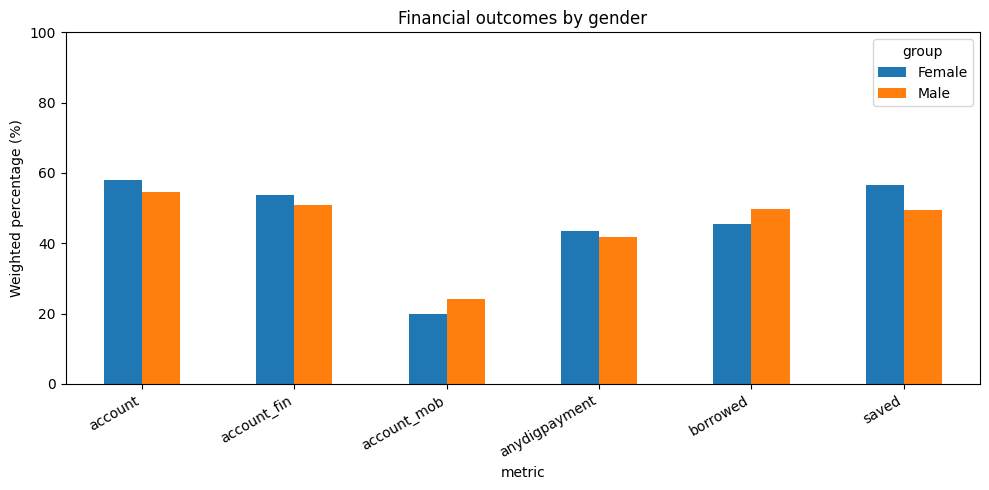

In [7]:
cross=pd.concat([by_group(dim,indicator) for dim in ["gender","income_quintile","residence"] for indicator in INDICATORS],ignore_index=True)
display(cross.head(20))
pivot=cross.query("dimension=='gender'").pivot(index="metric",columns="group",values="rate_pct")
display(pivot.round(1))
pivot.plot(kind="bar",figsize=(10,5))
plt.ylabel("Weighted percentage (%)");plt.title("Financial outcomes by gender")
plt.xticks(rotation=30,ha="right");plt.ylim(0,100);plt.tight_layout();plt.show()


## 8. Account gap table and simple data validation


In [8]:
gap_rows=[]
for dim in dimensions+["income_quintile"]:
    t=by_group(dim)
    valid=t.loc[~t.small_n_warning & t.rate_pct.notna()]
    if len(valid)<2: continue
    hi=valid.loc[valid.rate_pct.idxmax()]
    lo=valid.loc[valid.rate_pct.idxmin()]
    gap_rows.append({"dimension":dim,"highest_group":hi.group,"lowest_group":lo.group,"max_rate_pct":hi.rate_pct,"min_rate_pct":lo.rate_pct,"gap_pp":round(hi.rate_pct-lo.rate_pct,3)})
gaps=pd.DataFrame(gap_rows).sort_values("gap_pp",ascending=False)
display(gaps)
national=weighted_share(d,"account")[0]
print(f"National weighted account rate: {national:.2f}%")
print("Dataset coverage:",len(d),"survey respondents, year:",d.year.unique())
assert np.isclose(national,overview.loc[overview.metric.eq("account"),"rate_pct"].iloc[0])
assert not segments.rate_pct.dropna().gt(100).any()


National weighted account rate: 56.33%
Dataset coverage: 1068 survey respondents, year: [2024]


## 9. Save dashboard-ready aggregates LOCALLY

Files in `data/processed/` are ignored by Git. Use aggregated metrics only when connecting Google Sheets or Looker Studio. Review small cells before any publication.


In [9]:
overview.round(4).to_csv(out/"person1_overview_kpis.csv",index=False)
segments.to_csv(out/"person1_account_segments.csv",index=False)
cross.to_csv(out/"person1_cross_metrics.csv",index=False)
gaps.to_csv(out/"person1_gap_summary.csv",index=False)
print("Wrote 4 aggregate CSVs to",out)
print("Do not git add raw microdata or individual-level data.")


Wrote 4 aggregate CSVs to /content/Indonesia-Financial-Inclusion-Digital-Finance-Analytics/data/processed
Do not git add raw microdata or individual-level data.


## 10. Interpretation of EDA Results (Person 1)

**Status:** Preliminary descriptive findings from the original, checksum-verified 2024 Indonesia survey microdata. Final publication requires the Person 2 codebook mapping and the agreed cleaning integration (Notebooks 02 and 03).

### 10.1 National financial inclusion — the big picture

| Indicator | Survey-weighted share |
|---|---:|
| Owns any account (`account`) | **56.33%** |
| Financial institution account (`account_fin`) | 52.39% |
| Mobile money account (`account_mob`) | 22.01% |
| Used digital payment (`anydigpayment`) | 42.69% |
| Saved money (`saved`) | 52.99% |
| Borrowed money (`borrowed`) | 47.64% |

**Interpretation:** Account ownership is above 50%, but the survey still points to an important inclusion gap. Use of digital payments (42.69%) is below overall account ownership (56.33%). These are **different, potentially overlapping indicators**; do not treat their difference as a measured conversion funnel or add the rates together.

### 10.2 Income gradient — a large gap, but not perfectly monotonic

| Income quintile | Weighted account ownership |
|---|---:|
| Q1, lowest income | 46.425% |
| Q2 | 50.406% |
| Q3 | 46.203% |
| Q4 | 60.590% |
| Q5, highest income | 78.002% |

The **Q5 minus Q1 gap is 31.577 percentage points** (about **31.58 pp**). The *maximum minus minimum among all quintiles* is **31.799 pp**, comparing Q5 with Q3; this is why the Notebook 04 gap table lists Q3 rather than Q1 as its minimum. The pattern is **not perfectly monotonic**, because Q3 is marginally below Q1. Avoid saying that the ownership rate necessarily rises with every income quintile.

**Business/policy question to investigate:** Could affordability, onboarding and access barriers partly explain the lower account ownership among lower-income groups? This analysis cannot establish causal mechanisms.

### 10.3 Education — largest observed descriptive gap

| Education group | Weighted ownership | Unweighted n |
|---|---:|---:|
| Primary or less | 37.638% | 380 |
| Secondary | 66.268% | 646 |
| Tertiary or more | 85.607% | 41 |

The difference between **tertiary or more** and **primary or less** is **47.969 pp** (about **47.97 pp**), the largest *descriptive* gap among the segment dimensions examined. The tertiary group has only **41 respondents**, so do **not** claim the gap is statistically significant or causally attributable to education.

**Data-quality note:** One respondent has missing `educ`. The original Colab output displayed that missing segment with `n=1` and a 0% rate. This category **must be excluded from substantive comparisons and public charts**, not interpreted as an education category. The code now drops missing subgroup labels; its original four-panel chart/output is withheld from this GitHub snapshot. Rerun the revised plotting cell to regenerate a safe chart.

### 10.4 Age — a pronounced descriptive gradient

| Age group | Weighted ownership |
|---|---:|
| 15–24 | 61.993% |
| 25–34 | **70.135%** |
| 35–44 | 61.054% |
| 45–54 | 45.226% |
| 55+ | **39.519%** |

The difference between the highest age group rate (25–34) and the lowest (55+) is **30.616 pp** (about **30.62 pp**). This suggests an age-related inclusion disparity worth exploring. It does not show whether age itself causes the difference.

### 10.5 Gender and rural/urban residence — comparatively small differences

| Segment | Weighted ownership |
|---|---:|
| Female | 58.031% |
| Male | 54.639% |
| Urban | 56.666% |
| Rural | 56.030% |

The female–male difference is **3.392 pp**; the urban–rural difference is **0.636 pp**. Both are much smaller *descriptively* than the education, income and age gaps. **Neither was tested for statistical significance.** Do not generalize to specific Indonesian provinces: this file contains no province identifier.

Other gender comparisons in the output show **mobile money** account ownership at **24.131% for men vs 19.878% for women**, while saving is **56.463% for women vs 49.555% for men**. Inclusion dimensions can have different patterns; avoid an oversimplified claim that one gender always leads.

### 10.6 Suggested dashboard narrative (Person 1 — Pages 1 and 2)

- **Page 1: Financial Inclusion Overview.** Present six weighted KPI cards, a comparative bar chart of indicators, survey year (2024), sample size (n=1,068), and a short methodology note on weights.
- **Page 2: Inclusion Gap & Demographics.** Compare ownership by income Q1–Q5, education, age group, gender and rural/urban residence. Show **percentage-point** gaps instead of ambiguous percent changes, and add unweighted subgroup n as a contextual quality measure.
- **Headline:** "Income, education and age disparities are much more pronounced than the gender or urban/rural differences in this 2024 descriptive sample."
- **Candidate interventions to explore, not proven causal recommendations:** affordability and accessible services for lower-income groups; inclusive account-opening support; age-friendly financial onboarding; and evidence gathering on financial literacy or product usability.

### 10.7 Methodology and limitations

1. Shares are computed with `wgt` as `sum(wgt × binary_indicator) / sum(wgt)` over valid responses. Percentage-point gaps are differences between weighted shares.
2. This is a **single-year cross-sectional survey (2024)**. It cannot establish causal effects or trends over multiple years.
3. Small groups require caution: the tertiary education subgroup has `n=41` and the missing education subgroup has `n=1` (excluded). The rule `n<30` is a **simple flag**, not a statistical uncertainty estimate.
4. No survey-design-based confidence intervals or hypothesis tests were computed. In particular, small gender and residence differences should **not** be described as statistically meaningful.
5. Validate indicator code values, time windows and eligible response universes against Notebook 02 and the World Bank codebook. Do not treat skip-logic missing values as zero.
6. Keep the raw ZIP and respondent-level transformed data out of public GitHub. This notebook's respondent preview and the unsafe single-record subgroup output have been removed from the public execution snapshot.

### 10.8 Next steps / handoff checklist

- [x] Execute EDA on validated original microdata and inspect weighted results.
- [x] Document preliminary interpretation and main descriptive gaps.
- [ ] Have Person 2 complete `02_variable_mapping.ipynb` (codes, eligible populations and skip logic).
- [ ] Finish joint `03_cleaning_integration.ipynb`; establish shared validated mappings and metric formulas.
- [ ] **Rerun Notebook 04** with the approved categories/data definitions, especially the revised chart that excludes missing education.
- [ ] Review small samples, benchmark national indicators to official Findex definitions and check all denominators.
- [ ] Export the four aggregate CSVs in `data/processed/` (local/privately stored, not committed by default).
- [ ] Upload only approved aggregated tables to Google Sheets or BigQuery and connect Looker Studio.
- [ ] Build Page 1 and Page 2; cross-review calculations, filters, chart labels and storyline.
- [ ] Add reviewed dashboard screenshots and the Looker Studio link to `dashboard/README.md`.
